In [1]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from simulate_bounds import EPS_INTERVAL, MODE_DEGREE

from rayfish.classical_fisher_information.measurement_basis.hermite_gaussian_basis import (  # noqa: E501
    _mix_modes_via_unitary,
    measurement_basis,
)
from visualize_helpers import (
    create_fig_and_ax,
    latexify,
    plot_individual_fi,
    plot_mode_mixing_sweep,
)

latexify()
FORMAT = "pdf"
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
    "Blues",
]

In [2]:
%matplotlib inline

In [ ]:
selected_eps = [0.0, 0.04, 0.07, 0.1, 0.3]

# Mode leakage

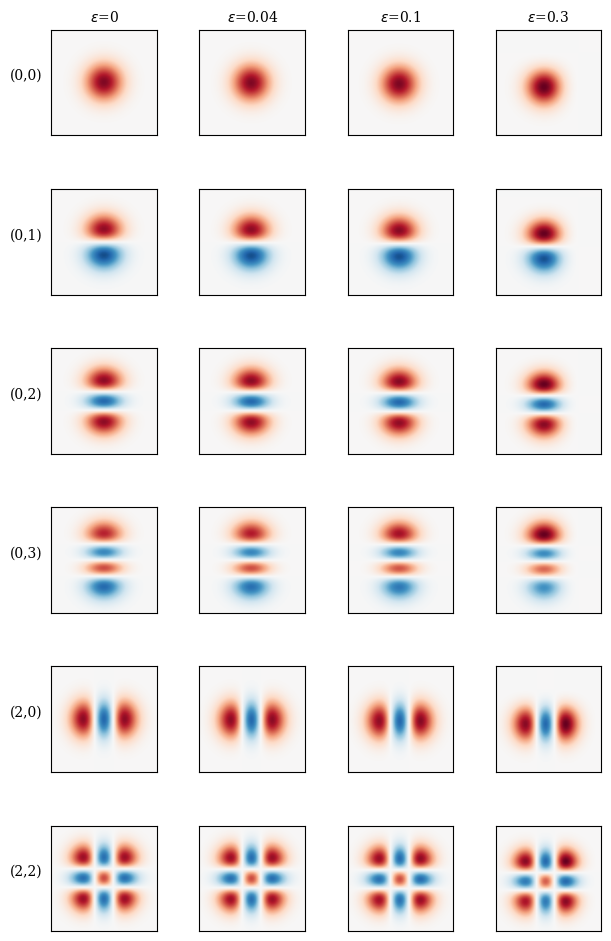

In [5]:
md = 4
fig, _ = plot_mode_mixing_sweep(
    measurement_basis(md),
    selected_eps,
    _mix_modes_via_unitary,
    mode_degree=md,
    mode_indices=[
        i * md + j for (i, j) in [(0, 0), (0, 1), (0, 2), (0, 3), (2, 0), (2, 2)]
    ],
)

# Load data

In [6]:
coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

baseline_ms = np.load("baseline_fi_ms.npy")
baseline_ms_inv = np.load("baseline_fi_ms_inv.npy")

fis = []
fis_inv = []
for mixing_eps in selected_eps:
    fis.append(np.load(f"fi_ms_eps_{mixing_eps:.2f}.npy"))
    fis_inv.append(np.load(f"fi_ms_inv_eps_{mixing_eps:.2f}.npy"))

In [20]:
def eps_to_db(eps: float) -> float:
    """Convert eps to DB."""
    return 20 * np.log10(np.sin(eps)) if eps > 0 else -np.inf


def _rep_color(name: str, t: float = 0.85) -> tuple[float, float, float, float]:
    clipped = mcolors.ListedColormap(cm.get_cmap(name)(np.linspace(0.3, 1.0, 256)))
    return clipped(t)


handles = []
for c, e in zip(continuous_cmaps[: len(fis)], selected_eps):
    label = f"{eps_to_db(e):.2f}" if e > 0 else "baseline"
    handles.append(Line2D([], [], color=_rep_color(c), lw=3, label=label))

/var/folders/_5/qn4m8hy526b4gsrvq_fc20x00000gn/T/ipykernel_3191/3606476012.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  clipped = mcolors.ListedColormap(cm.get_cmap(name)(np.linspace(0.3, 1.0, 256)))


# s param

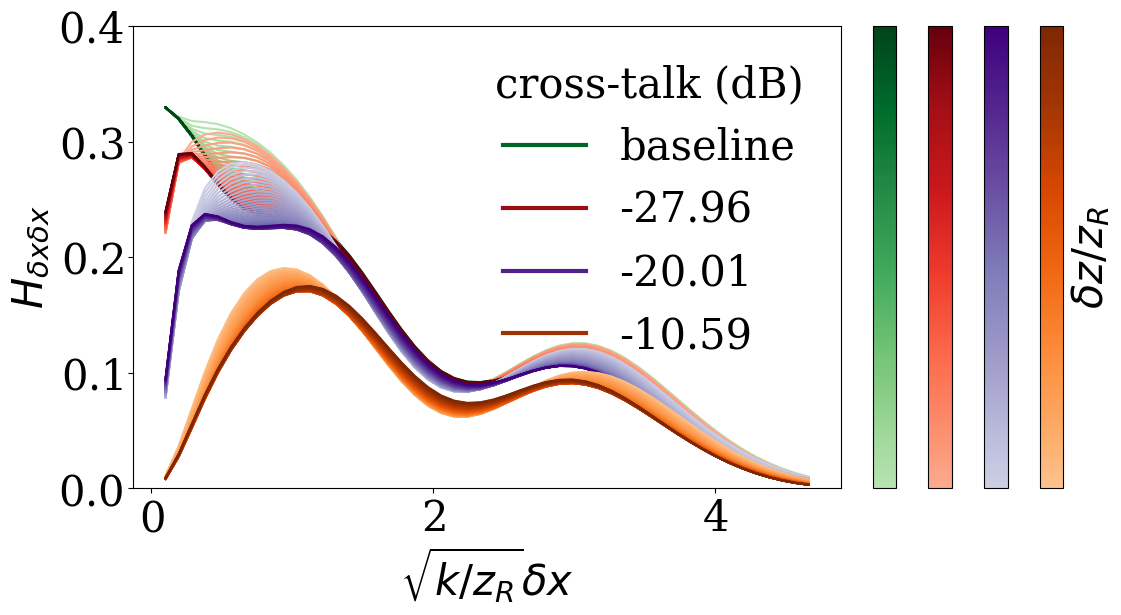

In [21]:
fig, axs = create_fig_and_ax(len(fis))
for i, fi in enumerate(fis):
    ms_cm = plot_individual_fi(
        fig,
        axs,
        np.sum(fi, axis=2)[:, :, 0, 0],
        x_range,
        p_range,
        continuous_cmaps[i],
        i + 1,
        "",
    )


axs[0].legend(handles=handles, title="cross-talk (dB)", frameon=False, loc="best")
axs[0].set_ylim(0, 0.4)
axs[len(fis)].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

# fig.savefig(f"s_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

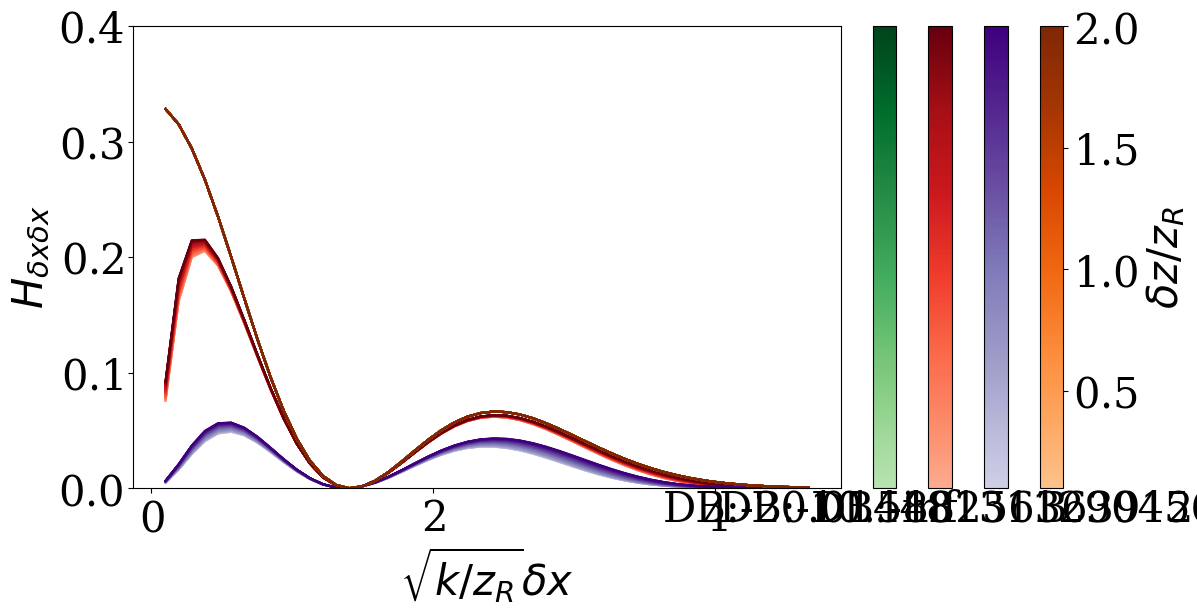

In [14]:
x_index = 1
y_index = 0
mode_index = x_index * MODE_DEGREE + y_index

fig, axs = create_fig_and_ax(len(fis) + 1)
for i, fi in enumerate(fis):
    ms_cm = plot_individual_fi(
        fig,
        axs,
        fi[:, :, mode_index, 0, 0],
        x_range,
        p_range,
        continuous_cmaps[i],
        i + 1,
        f"DB:{eps_to_db(EPS_INTERVAL[i])}",
    )

ms_cm_baseline = plot_individual_fi(
    fig,
    axs,
    baseline_ms[:, :, mode_index, 0, 0],
    x_range,
    p_range,
    continuous_cmaps[len(fis)],
    len(fis) + 1,
    "B",
    False,
)


axs[0].set_ylim(0, 0.4)
axs[len(fis) + 1].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

# fig.savefig(
#     f"s_param_individual_mode_contributions.{FORMAT}",
#     format=FORMAT,
#     bbox_inches="tight",
# )
plt.show()

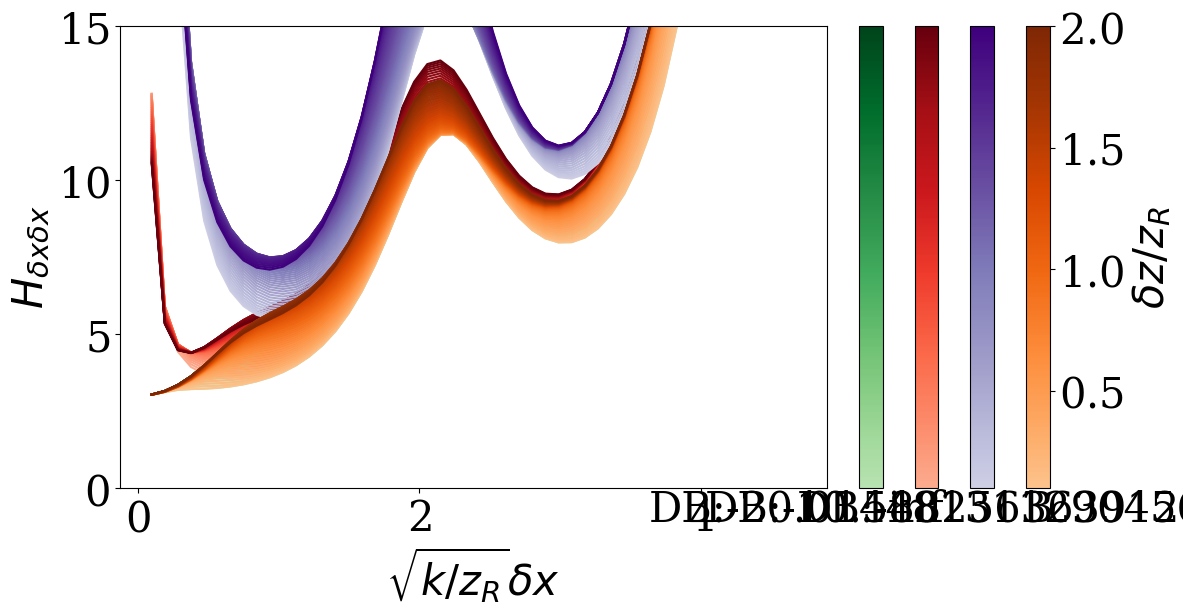

In [15]:
fig, axs = create_fig_and_ax(len(fis) + 1)
for i, fi in enumerate(fis_inv):
    ms_cm = plot_individual_fi(
        fig,
        axs,
        fi[:, :, 0, 0],
        x_range,
        p_range,
        continuous_cmaps[i],
        i + 1,
        f"DB:{eps_to_db(EPS_INTERVAL[i])}",
    )

ms_cm_baseline = plot_individual_fi(
    fig,
    axs,
    baseline_ms_inv[:, :, 0, 0],
    x_range,
    p_range,
    continuous_cmaps[len(fis)],
    len(fis) + 1,
    "B",
    False,
)


axs[0].set_ylim(0, 15)
axs[len(fis) + 1].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")


# fig.savefig(f"s_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

# p param

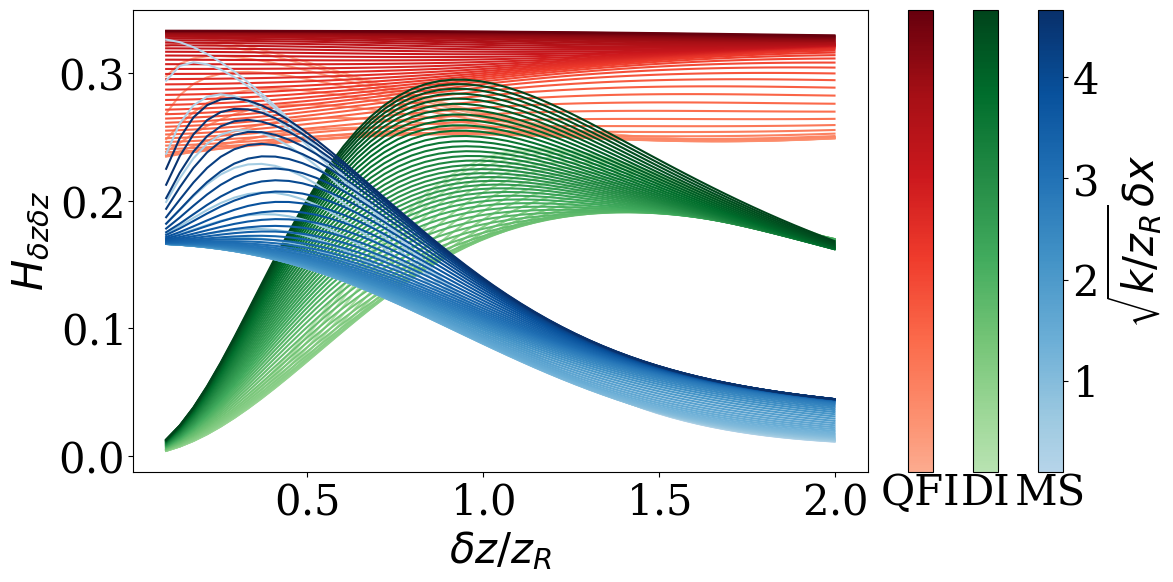

In [ ]:
# fig, axs = create_fig_and_ax(3)

# qfi_cm = plot_individual_fi(
#     fig, axs, np.transpose(qfi_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
# )
# di_cm = plot_individual_fi(
#     fig, axs, np.transpose(fi_di_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
# )
# qfi_cm = plot_individual_fi(
#     fig,
#     axs,
#     np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
#     p_range,
#     x_range,
#     "Blues",
#     3,
#     "MS",
#     False,
# )

# axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
# axs[0].set_xlabel(r"$\delta z / z_R$")
# axs[0].set_ylabel(r"$H_{\delta z \delta z}$")


# fig.savefig(f"p_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")

# plt.show()

# fig, axs = create_fig_and_ax(len(fis))
# for i, fi in enumerate(fis):
#     ms_cm = plot_individual_fi(
#         fig,
#         axs,
#         np.sum(fi, axis=2)[:, :, 1, 1],
#         p_range,
#         x_range,
#         continuous_cmaps[i],
#         i + 1,
#         "",
#     )


# axs[0].legend(handles=handles, title="cross-talk (dB)", frameon=False, loc="best")
# axs[0].set_ylim(0, 0.4)
# axs[len(fis)].set_ylabel(r"$\delta z / z_R$")
# axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
# axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

# # fig.savefig(f"s_param_fi_comparison.{FORMAT}", format=FORMAT, bbox_inches="tight")
# plt.show()

{'x': array([ 0.        , -1.73205081,  0.        ,  1.15470054]), 'y': array([ 0.        , -1.73205081,  0.        ,  1.15470054])}


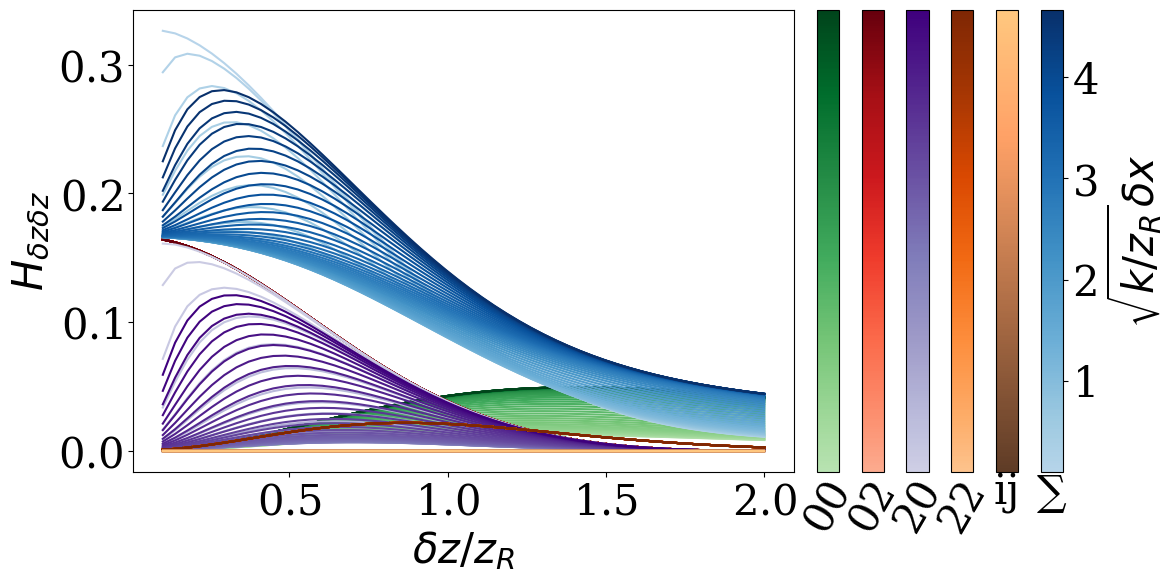

In [ ]:
# good_cmaps = filter_pub_friendly_continuous()

# n_axes = 5
# fig, axs = create_fig_and_ax(n_axes + 1)

# counter = 0
# for i, j in [(0, 0), (0, 2), (2, 0), (2, 2)]:
#     plot_individual_fi(
#         fig,
#         axs,
#         np.transpose(fi_ms_[:, :, i * mode_degree + j, 1, 1]),
#         p_range,
#         x_range,
#         good_cmaps[counter],
#         counter + 1,
#         f"{i}{j}",
#         rotation=60,
#     )
#     counter += 1

# plot_individual_fi(
#     fig,
#     axs,
#     np.transpose(fi_ms_[:, :, 1 * mode_degree + 1, 1, 1]),
#     p_range,
#     x_range,
#     good_cmaps[-2],
#     n_axes,
#     "ij",
# )

# plot_individual_fi(
#     fig,
#     axs,
#     np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
#     p_range,
#     x_range,
#     good_cmaps[-1],
#     n_axes + 1,
#     "∑",
#     False,
# )


# axs[n_axes + 1].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
# axs[0].set_xlabel(r"$\delta z / z_R$")
# axs[0].set_ylabel(r"$H_{\delta z \delta z}$")

# fig.savefig(
#     f"p_param_individual_mode_contributions.{FORMAT}",
#     format=FORMAT,
#     bbox_inches="tight",
# )
# plt.show()

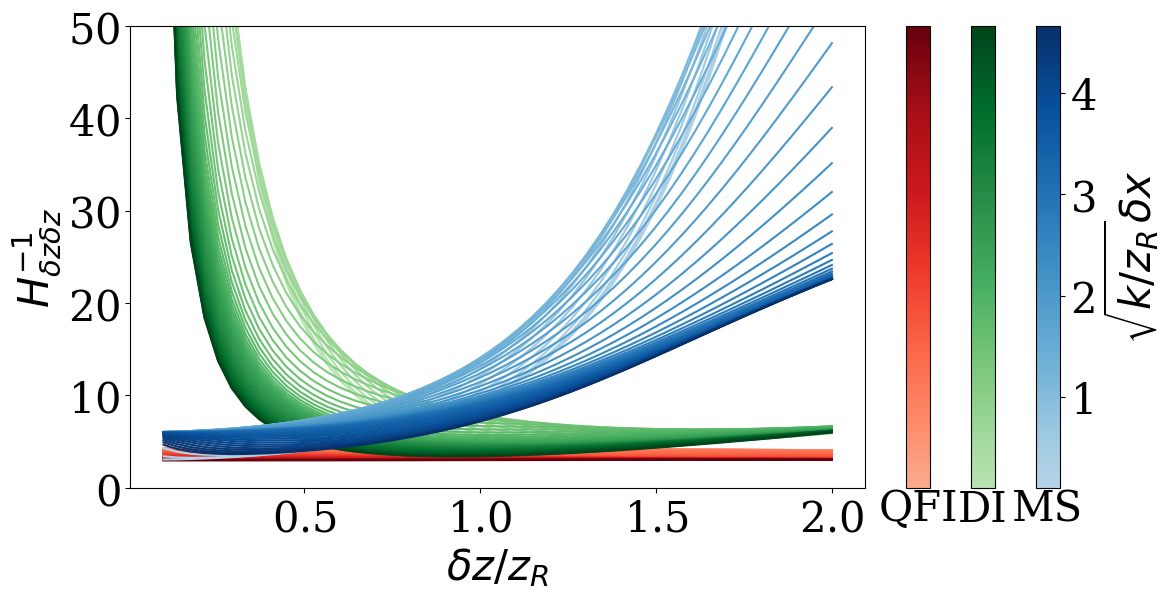

In [ ]:
# fig, axs = create_fig_and_ax(3)

# qfi_cm = plot_individual_fi(
#     fig,
#     axs,
#     np.transpose(fi_ms_inv_[:, :, 1, 1]),
#     p_range,
#     x_range,
#     "Blues",
#     3,
#     "MS",
#     False,
# )

# axs[0].set_ylim(0, 50)
# axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
# axs[0].set_xlabel(r"$\delta z / z_R$")
# axs[0].set_ylabel(r"$H^{-1}_{\delta z \delta z}$")

# fig.savefig(f"p_param_covariance.{FORMAT}", format=FORMAT, bbox_inches="tight")
# plt.show()